# Build the Bike Share Toronto training table

This notebook turns the raw station snapshots in `data/` into one training table for the MIE1517 availability model. It follows `docs/bikeshare_dataset_build_plan.md`.

**The question the model answers:** "If I arrive at station S in `h` minutes (2 to 15), will there be at least one classic bike, one e-bike, and one free dock?"

**What one row is:** a pretend rider query from the past: one station, one anchor time `t`, one horizon `h`. Inputs describe what was knowable at `t`. Labels come from the real snapshot at about `t + h`.

**Only low counts are kept.** A station showing 20 classic bikes will almost surely still have one in 15 minutes, so that row teaches the model nothing. An anchor is kept only if at least one of its three counts is `<= LOW_COUNT_K` (2). Counts of 0 are included, so the model also answers "will one appear?". Each row has a mask per label (`m_classic`, `m_ebike`, `m_dock`) that the training code uses for a masked loss.

**The most important rule:** no information from after `t` may reach an input column. Each step below says how it keeps to that rule.

### Where this differs from the build plan

1. **Notebook, not script.** The `--inputs`, `--out-dir` and `--parquet` arguments are constants in the config cell.
2. **Weather is per weather station, not city-wide.** The plan assumes one weather series and says to ignore `nearest_bike_id`. That column is really a weather station ID: it has 3 values, each bike station maps to exactly one, and they differ by 1.6°C on average. Each bike station here uses its own weather station. The output columns are unchanged.
3. **Rows with empty `capacity` are dropped** (419 rows). The plan doesn't cover them, and they would break the no-missing-values check.

### Setup (once, in a terminal)

```bash
conda create -y -n ebike --override-channels -c conda-forge python=3.12 pip
conda activate ebike
pip install -r requirements.txt
python -m ipykernel install --user --name ebike
```

Then pick the `ebike` kernel here. `--override-channels -c conda-forge` avoids the Anaconda terms-of-service prompt that plain `conda create` hits on this machine.

### Running it

Use **Run All**. Steps 2 and 3 load and clean 11 GB, then save the result. Later runs reuse that saved file, and it rebuilds by itself if the CSV files change. The full run took about 2 minutes in testing and peaked at about 13 GB of memory, so have 15 GB free.

## 0. Imports and configuration

Everything you may want to change is in this cell. The constants match section 3 of the build plan.

In [2]:
import gc
import glob
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pa_csv
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INPUT_GLOB = str(PROJECT_ROOT / "data" / "snapshots_with_weather*.csv")
OUT_DIR = PROJECT_ROOT / "data" / "processed"
WRITE_PARQUET = True       # also write training_table.parquet (much faster to load than the CSV)
REBUILD_CLEAN = False      # True forces Steps 2-3 to run again even if the saved clean file is valid

# Build settings
ANCHOR_EVERY_MIN   = 10        # anchor grid spacing
ANCHOR_TOL_MIN     = 3         # anchor must use a reading at most this old
HORIZONS           = list(range(2, 16))      # 2, 3, ..., 15
N_HORIZONS_PER_ANCHOR = 3
MAX_H_MIN          = 15        # drop rows whose actual gap h (to the label reading) exceeds this
LOW_COUNT_K        = 2         # a label is "uncertain" (masked in) when its count now is <= this
LAG_MINUTES        = [10, 30]
LAG_TOL_MIN        = 6         # lag value must come from a reading at most this old
LABEL_TOL_MIN      = 3         # label reading must be within this many minutes AFTER t+h
WEATHER_FFILL_MAX_MIN = 120
SPLIT_FRACTIONS    = (0.70, 0.15, 0.15)       # train / val / test, by time
SPLIT_DATES        = None      # optional override: ("YYYY-MM-DD", "YYYY-MM-DD") = (val_start, test_start), Toronto local
RANDOM_SEED        = 1517
LOCAL_TZ           = "America/Toronto"

# One station followed through every step so you can watch a query being built
EXAMPLE_STATION_ID = 7000
EXAMPLE_T = None           # chosen in Step 5

OUT_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_PATH = OUT_DIR / "readings_clean.parquet"
NAMES_PATH = OUT_DIR / "station_names.parquet"
META_PATH = OUT_DIR / "readings_clean_meta.json"
print("Input:", INPUT_GLOB)
print("Output:", OUT_DIR)

Input: /home/zweminhtetaung/mie1517_ebike_project/data/snapshots_with_weather*.csv
Output: /home/zweminhtetaung/mie1517_ebike_project/data/processed


### Tracking helpers

`log_step` records rows before and after each step in `ledger`. `show_ledger()` prints the running table, and `show_example()` shows the example station at the current step.

In [3]:
ledger = {}

def log_step(step: str, before: int, after: int, unit: str = "rows") -> None:
    removed = before - after
    pct = 100 * removed / before if before else 0.0
    ledger[step] = {"unit": unit, "before": before, "after": after, "removed": removed, "pct_removed": round(pct, 2)}
    print(f"{step}: {before:,} -> {after:,} {unit} ({removed:,} removed, {pct:.2f}%)")

def show_ledger() -> None:
    display(pd.DataFrame.from_dict(ledger, orient="index"))

def show_example(df: pd.DataFrame, columns: list | None = None, n: int = 6) -> None:
    mask = df["station_id"] == EXAMPLE_STATION_ID
    if EXAMPLE_T is not None and "t" in df.columns:
        mask &= df["t"] == EXAMPLE_T
    display(df.loc[mask, columns if columns else df.columns].head(n))

def to_ns_utc(s: pd.Series) -> pd.Series:
    """merge_asof needs both time columns in exactly the same unit."""
    return pd.to_datetime(s, utc=True).astype("datetime64[ns, UTC]")

## 1. The pipeline functions, tested on the plan's worked example

All the time lookups live here so they can be tested on a tiny example before touching 11 GB. The same functions run on the real data below.

Every lookup uses `pd.merge_asof`, which finds the closest row in time:

| Lookup | Direction | Tolerance | Why |
|---|---|---|---|
| Anchor ("now") | backward | 3 min | Only readings at or before `t` |
| Lags | backward | 6 min | Only readings at or before `t - k` |
| Labels | **forward** | 3 min | Only readings at or after `t + h`. "nearest" could pick a reading from before the target, and at small `h` the label could equal the input |
| Weather | backward | 120 min | Only weather at or before `t` |

In [4]:
def build_weather(readings: pd.DataFrame, ffill_max_min: int) -> pd.DataFrame:
    """One weather series per weather station. Forward-fill only, limited by age. Never back-fill."""
    weather = (
        readings[["weather_id", "ts", "temp", "relative_humidity"]]
        .groupby(["weather_id", "ts"], sort=True)
        .first()   # first non-null value at this time
        .reset_index()
    )
    max_age = pd.Timedelta(minutes=ffill_max_min)
    by_station = weather["weather_id"]
    for col in ["temp", "relative_humidity"]:
        last_valid = weather["ts"].where(weather[col].notna()).groupby(by_station).ffill()
        filled = weather[col].groupby(by_station).ffill()
        weather[col] = filled.where(weather["ts"] - last_valid <= max_age)
    return weather.sort_values("ts", kind="stable").reset_index(drop=True)


LABEL_NOW = {"classic": "classic_now", "ebike": "ebike_now", "dock": "docks_now"}   # label name -> its count at t


def is_low_count(df: pd.DataFrame, k: int) -> pd.Series:
    """True where at least one of the three counts now is <= k. Uses values at t only."""
    return (df["classic_now"] <= k) | (df["ebike_now"] <= k) | (df["docks_now"] <= k)


def add_masks(rows: pd.DataFrame, k: int) -> pd.DataFrame:
    """m_* = 1 where that label's count now is <= k. The training loss only uses a label where its mask is 1."""
    for name, now_col in LABEL_NOW.items():
        rows[f"m_{name}"] = (rows[now_col] <= k).astype("int8")
    return rows


def build_anchors(readings: pd.DataFrame, grid: pd.DatetimeIndex, tol_min: int) -> pd.DataFrame:
    """For each station and grid time, take the latest reading at or before that time."""
    stations = np.sort(readings["station_id"].unique())
    pairs = pd.DataFrame({
        "t": grid.repeat(len(stations)),
        "station_id": np.tile(stations, len(grid)),
    })
    now = readings[["ts", "station_id", "classic", "ebike", "docks", "renting", "returning",
                    "capacity", "latitude", "longitude", "weather_id"]].rename(columns={
        "ts": "anchor_ts", "classic": "classic_now", "ebike": "ebike_now", "docks": "docks_now",
        "renting": "renting_now", "returning": "returning_now", "latitude": "lat", "longitude": "lon",
    })
    anchors = pd.merge_asof(
        pairs, now, left_on="t", right_on="anchor_ts", by="station_id",
        direction="backward", tolerance=pd.Timedelta(minutes=tol_min),
    )
    anchors = anchors.dropna(subset=["anchor_ts"]).reset_index(drop=True)
    return anchors.astype({
        "classic_now": "int16", "ebike_now": "int16", "docks_now": "int16", "capacity": "int16",
        "renting_now": "bool", "returning_now": "bool", "weather_id": "int32",
    })


def add_lag(anchors: pd.DataFrame, readings: pd.DataFrame, k: int, tol_min: int) -> pd.DataFrame:
    """Add classic/ebike/docks as they were k minutes before t. Missing stays NaN here."""
    past = readings[["ts", "station_id", "classic", "ebike", "docks"]].rename(columns={
        "ts": f"lag_ts_{k}", "classic": f"classic_tm{k}", "ebike": f"ebike_tm{k}", "docks": f"docks_tm{k}",
    })
    left = anchors.assign(lag_target=anchors["t"] - pd.Timedelta(minutes=k))
    merged = pd.merge_asof(
        left, past, left_on="lag_target", right_on=f"lag_ts_{k}", by="station_id",
        direction="backward", tolerance=pd.Timedelta(minutes=tol_min),
    )
    return merged.drop(columns="lag_target")


def sample_horizons(anchors: pd.DataFrame, horizons: list, n: int, seed: int) -> pd.DataFrame:
    """Give each anchor n distinct random horizons, making one row per horizon."""
    rng = np.random.default_rng(seed)
    picks = rng.random((len(anchors), len(horizons))).argsort(axis=1)[:, :n]
    rows = anchors.loc[anchors.index.repeat(n)].reset_index(drop=True)
    rows["h_target"] = np.asarray(horizons, dtype="int8")[picks].ravel()
    return rows


def attach_labels(rows: pd.DataFrame, readings: pd.DataFrame, tol_min: int) -> pd.DataFrame:
    """Find the first reading at or after t + h_target, then build the 0/1 labels."""
    future = readings[["ts", "station_id", "classic", "ebike", "docks", "renting", "returning"]].rename(columns={
        "ts": "label_ts", "classic": "classic_future", "ebike": "ebike_future", "docks": "docks_future",
        "renting": "renting_future", "returning": "returning_future",
    })
    left = rows.assign(label_target=rows["t"] + pd.to_timedelta(rows["h_target"].astype("int64"), unit="min"))
    left = left.sort_values("label_target", kind="stable")
    merged = pd.merge_asof(
        left, future, left_on="label_target", right_on="label_ts", by="station_id",
        direction="forward", tolerance=pd.Timedelta(minutes=tol_min),
    )
    merged = merged.dropna(subset=["label_ts"]).reset_index(drop=True)
    merged = merged.astype({
        "classic_future": "int16", "ebike_future": "int16", "docks_future": "int16",
        "renting_future": "bool", "returning_future": "bool",
    })
    merged["h"] = ((merged["label_ts"] - merged["t"]).dt.total_seconds() / 60).round(1).astype("float32")
    merged["y_classic"] = ((merged["classic_future"] >= 1) & merged["renting_future"]).astype("int8")
    merged["y_ebike"] = ((merged["ebike_future"] >= 1) & merged["renting_future"]).astype("int8")
    merged["y_dock"] = ((merged["docks_future"] >= 1) & merged["returning_future"]).astype("int8")
    return merged

### Test on section 6 of the build plan

Station 7000 at `t = 08:00`. Expected results:

- With the plan's readings, the anchor is found but **dropped**, because the nearest reading before 07:50 is 19.7 minutes old.
- The anchor passes the low-count filter (`ebike_now = 1`), with masks `m_classic, m_ebike, m_dock` = 0, 1, 0.
- With lag readings added, horizons 4, 12, 14 give `h` = 4.2, 12.5, 14.3 and `y_ebike` = 1, 1, 0.
- If the 14-minute reading came at 08:15:40 instead, `h` = 15.7 > 15 and that row would be dropped.

A second test checks that weather forward-fills up to the limit, stays separate per weather station, and never back-fills.

In [5]:
def example_readings(extra: list | None = None) -> pd.DataFrame:
    rows = [("07:30:20", 35, 3, 9), ("07:50:15", 37, 2, 8), ("07:59:40", 38, 1, 8),
            ("08:04:10", 38, 1, 8), ("08:12:30", 38, 1, 8), ("08:14:20", 39, 0, 8)] + (extra or [])
    df = pd.DataFrame(rows, columns=["clock", "classic", "ebike", "docks"]).sort_values("clock")
    df = df.assign(
        ts=to_ns_utc("2026-10-24 " + df["clock"]), station_id=np.int32(7000), renting=True, returning=True,
        capacity=np.int16(47), latitude=43.64, longitude=-79.40, weather_id=np.int32(48549),
    ).drop(columns="clock")
    return df.astype({"classic": "int16", "ebike": "int16", "docks": "int16"}).reset_index(drop=True)

grid = pd.DatetimeIndex(["2026-10-24 08:00:00"], tz="UTC").as_unit("ns")

# Part 1: the plan's readings. The anchor is found, then lost to the 10-minute lag.
r = example_readings()
a = build_anchors(r, grid, ANCHOR_TOL_MIN)
assert len(a) == 1 and (a.loc[0, "classic_now"], a.loc[0, "ebike_now"], a.loc[0, "docks_now"]) == (38, 1, 8)
assert add_lag(a, r, 10, LAG_TOL_MIN)["classic_tm10"].isna().all(), "07:30:20 is too old to be the 10-minute lag"

# Low-count filter: kept because ebike_now = 1. A count of exactly K is kept, K + 1 everywhere is not.
assert is_low_count(a, LOW_COUNT_K).all()
edge = pd.DataFrame({"classic_now": [LOW_COUNT_K, LOW_COUNT_K + 1], "ebike_now": [LOW_COUNT_K + 1] * 2, "docks_now": [LOW_COUNT_K + 1] * 2})
assert is_low_count(edge, LOW_COUNT_K).tolist() == [True, False]

# Part 2: "suppose the lags had been found"
r = example_readings(extra=[("07:29:50", 35, 3, 9), ("07:49:55", 37, 2, 8)])
a = build_anchors(r, grid, ANCHOR_TOL_MIN)
for k in LAG_MINUTES:
    a = add_lag(a, r, k, LAG_TOL_MIN)
assert a[["classic_tm10", "classic_tm30"]].notna().all(axis=None)

fixed = a.loc[a.index.repeat(3)].reset_index(drop=True).assign(h_target=np.array([4, 12, 14], dtype="int8"))
labelled = attach_labels(fixed, r, LABEL_TOL_MIN).sort_values("h_target")
display(labelled[["t", "h_target", "label_ts", "h", "ebike_future", "y_ebike"]])
assert np.allclose(labelled["h"], [4.2, 12.5, 14.3], atol=0.01)
assert labelled["y_ebike"].tolist() == [1, 1, 0]
assert add_masks(labelled, LOW_COUNT_K)[["m_classic", "m_ebike", "m_dock"]].drop_duplicates().values.tolist() == [[0, 1, 0]]

# A late label reading (08:14:20 -> 08:15:40) gives h = 15.7, which Step 7 drops
late = r.copy()
late.loc[late["ts"].idxmax(), "ts"] += pd.Timedelta(seconds=80)
late_h = attach_labels(fixed, late, LABEL_TOL_MIN).query("h_target == 14")["h"]
assert np.allclose(late_h, [15.7], atol=0.01) and (late_h > MAX_H_MIN).all()

# Horizon sampling: distinct values per anchor, same result for the same seed
s1 = sample_horizons(a, HORIZONS, N_HORIZONS_PER_ANCHOR, RANDOM_SEED)
s2 = sample_horizons(a, HORIZONS, N_HORIZONS_PER_ANCHOR, RANDOM_SEED)
assert s1["h_target"].nunique() == N_HORIZONS_PER_ANCHOR and s1["h_target"].equals(s2["h_target"])

# Weather: empty before the first value, filled up to 120 min, empty after that, no mixing of stations
w_ts = to_ns_utc(pd.Series(["2026-10-24 08:00", "2026-10-24 09:00", "2026-10-24 10:00", "2026-10-24 11:00", "2026-10-24 09:00"]))
w = pd.DataFrame({"ts": w_ts, "weather_id": [1, 1, 1, 1, 2],
                  "temp": [np.nan, 5.0, np.nan, np.nan, 20.0], "relative_humidity": [np.nan, 50.0, np.nan, np.nan, 60.0]})
w_out = build_weather(pd.concat([w, w.iloc[[1]].assign(ts=to_ns_utc(pd.Series(["2026-10-24 12:00"])).iloc[0], temp=np.nan, relative_humidity=np.nan)]), 120)
w1 = w_out[w_out["weather_id"] == 1].set_index(w_out.loc[w_out["weather_id"] == 1, "ts"].dt.hour)["temp"]
assert np.isnan(w1[8]) and w1[9] == 5.0 and w1[10] == 5.0 and w1[11] == 5.0 and np.isnan(w1[12])

print("All worked-example tests passed.")

,t,h_target,label_ts,h,ebike_future,y_ebike
0,2026-10-24 08:00:00+00:00,4,2026-10-24 08:04:10+00:00,4.2,1,1
1,2026-10-24 08:00:00+00:00,12,2026-10-24 08:12:30+00:00,12.5,1,1
2,2026-10-24 08:00:00+00:00,14,2026-10-24 08:14:20+00:00,14.3,0,0


All worked-example tests passed.


## 2. Load and combine (build plan Step 1)

Reads only the needed columns from each CSV, using small data types. A plain full load with text columns ran out of memory on this 30 GB machine, so:

- `name` is not kept in the main table. The latest name per station is set aside for the lookup file.
- `source` is stored as a category.

`nearest_bike_id` is renamed to `weather_id` (see the note at the top). `capacity` is stored as `47.0` in the CSVs, so it is read as a float and becomes an integer during cleaning.

This cell is skipped if a valid saved clean file exists.

In [6]:
USECOLS = ["ts", "station_id", "source", "capacity", "classic", "ebike", "docks", "renting", "returning",
           "latitude", "longitude", "name", "nearest_bike_id", "temp", "relative_humidity"]
DTYPES = {"station_id": "int32", "nearest_bike_id": "int32", "capacity": "float32",
          "classic": "float32", "ebike": "float32", "docks": "float32",
          "latitude": "float32", "longitude": "float32", "temp": "float32", "relative_humidity": "float32"}
SOURCES = ["live", "history", "live_citybikes"]

def to_bool(s: pd.Series) -> pd.Series:
    return s if s.dtype == bool else s.astype(str).str.strip().str.lower().eq("true")

def load_file(path: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    df = pd.read_csv(path, engine="pyarrow", usecols=USECOLS, dtype=DTYPES)
    df["ts"] = to_ns_utc(df["ts"])
    df["renting"] = to_bool(df["renting"])
    df["returning"] = to_bool(df["returning"])
    df["source"] = pd.Categorical(df["source"], categories=SOURCES)
    names = df.loc[df.groupby("station_id")["ts"].idxmax(), ["station_id", "ts", "name"]]
    return df.drop(columns="name").rename(columns={"nearest_bike_id": "weather_id"}), names

input_files = sorted(glob.glob(INPUT_GLOB))
assert input_files, f"No files match {INPUT_GLOB}"
fingerprint = {Path(f).name: Path(f).stat().st_size for f in input_files}

cache_ok = CLEAN_PATH.exists() and NAMES_PATH.exists() and META_PATH.exists() \
    and json.loads(META_PATH.read_text())["fingerprint"] == fingerprint
use_cache = cache_ok and not REBUILD_CLEAN

if use_cache:
    print("Valid clean file found, skipping the load. Set REBUILD_CLEAN = True to force it.")
else:
    start = time.time()
    parts, name_parts = [], []
    for path in input_files:
        df, names = load_file(path)
        parts.append(df)
        name_parts.append(names)
        print(f"{Path(path).name}: {len(df):,} rows, {df.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory")
    raw = pd.concat(parts, ignore_index=True)
    del parts
    gc.collect()
    station_names = (pd.concat(name_parts).sort_values("ts").drop_duplicates("station_id", keep="last")
                     [["station_id", "name"]].reset_index(drop=True))
    station_names["name"] = station_names["name"].str.strip()
    print(f"\nCombined: {len(raw):,} rows, {raw.memory_usage(deep=True).sum() / 1e9:.2f} GB, {time.time() - start:.0f} s")
    print("Time range:", raw["ts"].min(), "to", raw["ts"].max())
    display(raw["source"].value_counts().to_frame("rows"))
    display(raw.head(3))

snapshots_with_weather0.csv: 10,000,000 rows, 0.51 GB in memory
snapshots_with_weather1.csv: 10,000,000 rows, 0.51 GB in memory
snapshots_with_weather2.csv: 10,000,000 rows, 0.51 GB in memory
snapshots_with_weather3.csv: 10,000,000 rows, 0.51 GB in memory
snapshots_with_weather4.csv: 10,000,000 rows, 0.51 GB in memory
snapshots_with_weather5.csv: 10,000,000 rows, 0.51 GB in memory
snapshots_with_weather6.csv: 7,010,542 rows, 0.36 GB in memory

Combined: 67,010,542 rows, 3.42 GB, 16 s
Time range: 2026-09-29 05:17:00+00:00 to 2026-10-28 08:31:30+00:00


,rows
source,
live,66296941
live_citybikes,713601
history,0


,ts,station_id,source,capacity,classic,ebike,docks,renting,returning,latitude,longitude,weather_id,temp,relative_humidity
0,2026-09-29 05:17:00+00:00,7000,live,47.0,44.0,1.0,1.0,True,True,43.639706,-79.396141,48549,18.6,73.0
1,2026-09-29 05:17:00+00:00,7001,live,23.0,3.0,0.0,12.0,True,True,43.664963,-79.383553,31688,17.9,75.0
2,2026-09-29 05:17:00+00:00,7002,live,19.0,0.0,0.0,16.0,True,True,43.667130,-79.399551,31688,17.9,75.0


## 3. Clean (build plan Step 2)

Applied in the plan's order, with the rows removed at each step printed:

1. Drop rows missing `ts`, `station_id`, `classic`, `ebike` or `docks`, then rows missing `capacity` (our addition).
2. Drop impossible values: negative counts, `capacity <= 0`.
3. Keep stations inside the Toronto bounding box.
4. Deduplicate: one reading per station per minute. Prefer `source == "live"`, then the earliest.
5. Sort by `station_id`, then `ts`.

Polls run about every 40 seconds, so expect step 4 to remove over a third of the rows. That loses very little, since consecutive polls are nearly identical. Rows with `renting`/`returning` False are kept here and handled at Steps 5 and 7.

The result is saved to `readings_clean.parquet` so you don't have to repeat this.

In [7]:
def clean_readings(df: pd.DataFrame) -> pd.DataFrame:
    log_step("read from CSV", len(df), len(df), "readings")

    n = len(df)
    df = df.dropna(subset=["ts", "station_id", "classic", "ebike", "docks"])
    log_step("clean 1a: missing key values", n, len(df), "readings")

    n = len(df)
    df = df.dropna(subset=["capacity"])
    log_step("clean 1b: missing capacity", n, len(df), "readings")

    n = len(df)
    impossible = (df["classic"] < 0) | (df["ebike"] < 0) | (df["docks"] < 0) | (df["capacity"] <= 0)
    df = df[~impossible]
    log_step("clean 2: impossible values", n, len(df), "readings")

    n = len(df)
    in_toronto = df["latitude"].between(43.4, 44.0) & df["longitude"].between(-79.8, -79.0)
    df = df[in_toronto]
    log_step("clean 3: outside Toronto", n, len(df), "readings")

    df = df.astype({"classic": "int16", "ebike": "int16", "docks": "int16", "capacity": "int16"})

    n = len(df)
    df = df.assign(minute=df["ts"].dt.floor("min"), not_live=df["source"].ne("live"))
    df = df.sort_values(["station_id", "minute", "not_live", "ts"], kind="stable")
    df = df.drop_duplicates(["station_id", "minute"]).drop(columns=["minute", "not_live"]).reset_index(drop=True)
    log_step("clean 4: same station and minute", n, len(df), "readings")

    # Step 5: one row per station-minute, so the sort above already gives station_id, ts order
    assert (df["station_id"].diff().fillna(0) >= 0).all()
    same_station = df["station_id"].eq(df["station_id"].shift())
    assert (df["ts"].diff()[same_station] > pd.Timedelta(0)).all()
    return df

if use_cache:
    readings = pd.read_parquet(CLEAN_PATH)
    readings["ts"] = to_ns_utc(readings["ts"])
    station_names = pd.read_parquet(NAMES_PATH)
    ledger.update(json.loads(META_PATH.read_text())["ledger"])
else:
    start = time.time()
    readings = clean_readings(raw)
    del raw
    gc.collect()
    readings.to_parquet(CLEAN_PATH, index=False)
    station_names.to_parquet(NAMES_PATH, index=False)
    META_PATH.write_text(json.dumps({"fingerprint": fingerprint, "ledger": ledger}, indent=2))
    print(f"\nCleaned and saved in {time.time() - start:.0f} s")

print(f"Clean readings: {len(readings):,} from {readings['station_id'].nunique():,} stations")
show_ledger()
show_example(readings)

read from CSV: 67,010,542 -> 67,010,542 readings (0 removed, 0.00%)
clean 1a: missing key values: 67,010,542 -> 67,010,542 readings (0 removed, 0.00%)
clean 1b: missing capacity: 67,010,542 -> 67,010,123 readings (419 removed, 0.00%)
clean 2: impossible values: 67,010,123 -> 67,002,890 readings (7,233 removed, 0.01%)
clean 3: outside Toronto: 67,002,890 -> 67,002,890 readings (0 removed, 0.00%)
clean 4: same station and minute: 67,002,890 -> 42,463,103 readings (24,539,787 removed, 36.62%)

Cleaned and saved in 26 s
Clean readings: 42,463,103 from 1,073 stations


,unit,before,after,removed,pct_removed
read from CSV,readings,67010542,67010542,0,0.00
clean 1a: missing key values,readings,67010542,67010542,0,0.00
clean 1b: missing capacity,readings,67010542,67010123,419,0.00
clean 2: impossible values,readings,67010123,67002890,7233,0.01
clean 3: outside Toronto,readings,67002890,67002890,0,0.00
clean 4: same station and minute,readings,67002890,42463103,24539787,36.62


,ts,station_id,source,capacity,classic,ebike,docks,renting,returning,latitude,longitude,weather_id,temp,relative_humidity
0,2026-09-29 05:17:00+00:00,7000,live,47,44,1,1,True,True,43.639706,-79.396141,48549,18.6,73.0
1,2026-09-29 05:50:03+00:00,7000,live,47,44,1,1,True,True,43.639706,-79.396141,48549,18.6,73.0
2,2026-09-29 05:51:02+00:00,7000,live,47,44,0,2,True,True,43.639706,-79.396141,48549,18.6,73.0
3,2026-09-29 05:52:02+00:00,7000,live,47,45,0,1,True,True,43.639706,-79.396141,48549,18.6,73.0
4,2026-09-29 05:53:02+00:00,7000,live,47,45,0,1,True,True,43.639706,-79.396141,48549,18.6,73.0
5,2026-09-29 05:54:02+00:00,7000,live,47,45,0,1,True,True,43.639706,-79.396141,48549,18.6,73.0


## 4. Weather series (build plan Step 3, changed to per weather station)

The data contains 3 weather stations, and every bike station belongs to one. We build one time series for each, then attach it at Step 8 through `weather_id`.

**Leakage rule:** gaps are forward-filled only, and only from a reading at most 120 minutes old. Nothing is back-filled, because that would copy future weather into the past. Weather values change at the top of each hour, which fits hourly observations carried forward, not future values.

The table and chart below show how different the three stations are.

,missing in readings,missing after forward-fill
temp,52164,120
relative_humidity,52164,120


temp                 relative_humidity            
            mean  min        max              mean   min   max
weather_id                                                    
31688       13.3  2.5  26.400000         69.900002  28.0  98.0
48549       13.4  2.6  23.700001         72.400002  29.0  99.0
51459       12.8  1.6  28.200001         69.000000  27.0  97.0

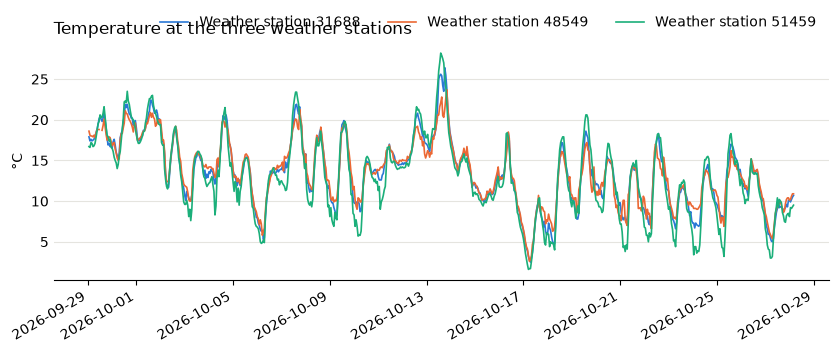

In [8]:
weather = build_weather(readings, WEATHER_FFILL_MAX_MIN)

missing_before = readings[["temp", "relative_humidity"]].isna().sum().rename("missing in readings")
missing_after = weather[["temp", "relative_humidity"]].isna().sum().rename("missing after forward-fill")
display(pd.concat([missing_before, missing_after], axis=1))
display(weather.groupby("weather_id")[["temp", "relative_humidity"]].agg(["mean", "min", "max"]).round(1))

readings = readings.drop(columns=["temp", "relative_humidity", "source"])
gc.collect()

hourly = (weather.set_index("ts").groupby("weather_id")["temp"].resample("1h").mean().unstack(0))
hourly.index = hourly.index.tz_convert(LOCAL_TZ).tz_localize(None)

fig, ax = plt.subplots(figsize=(10, 3.5))
for weather_id, color in zip(hourly.columns, ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.plot(hourly.index, hourly[weather_id], color=color, linewidth=1.2, label=f"Weather station {weather_id}")
ax.set_title("Temperature at the three weather stations", loc="left")
ax.set_ylabel("°C")
ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncols=3, loc="lower right", bbox_to_anchor=(1, 1))
fig.autofmt_xdate()
plt.show()

## 5. Anchors (build plan Step 4)

An anchor is a station at a grid time `t`. The grid runs every 10 minutes from the first reading to the last.

For each station and grid time we take the latest reading at or before `t`, and it can be at most 3 minutes old. If there is none (the poller had a gap, or the station didn't exist yet), that anchor doesn't exist.

**Leakage rule:** `t` is the grid time, and the "now" values always come from at or before `t`.

Stations with `renting` and `returning` both False are out of service and dropped. Expect very few: only 19 raw rows have this flag.

**Low-count filter.** An anchor is kept only if at least one of `classic_now`, `ebike_now`, `docks_now` is `<= LOW_COUNT_K`. It runs here, before the lag and label lookups, to save work. It only looks at values at `t`, so it cannot leak the future.

The build plan suggests working in batches if memory is tight. Every station and grid pair is only about 4.5M rows here, so one pass is fine.

In [9]:
start = time.time()
readings = readings.sort_values("ts", kind="stable").reset_index(drop=True)   # merge_asof needs time order

grid = pd.date_range(readings["ts"].iloc[0].floor("min"), readings["ts"].iloc[-1],
                     freq=f"{ANCHOR_EVERY_MIN}min").as_unit("ns")
possible = len(grid) * readings["station_id"].nunique()
print(f"Grid: {len(grid):,} times from {grid[0]} to {grid[-1]}")

anchors = build_anchors(readings, grid, ANCHOR_TOL_MIN)
log_step("anchors: no reading within tolerance", possible, len(anchors), "anchors")

n = len(anchors)
anchors = anchors[anchors["renting_now"] | anchors["returning_now"]].reset_index(drop=True)
log_step("anchors: out of service", n, len(anchors), "anchors")

n = len(anchors)
anchors = anchors[is_low_count(anchors, LOW_COUNT_K)].reset_index(drop=True)
log_step(f"anchors: no count <= {LOW_COUNT_K}", n, len(anchors), "anchors")

age_seconds = (anchors["t"] - anchors["anchor_ts"]).dt.total_seconds()
print(f"Age of the 'now' reading: median {age_seconds.median():.0f} s, max {age_seconds.max():.0f} s  ({time.time() - start:.0f} s)")
show_example(anchors, ["station_id", "t", "anchor_ts", "classic_now", "ebike_now", "docks_now", "capacity"], n=3)

Grid: 4,196 times from 2026-09-29 05:17:00+00:00 to 2026-10-28 08:27:00+00:00
anchors: no reading within tolerance: 4,502,308 -> 4,238,743 anchors (263,565 removed, 5.85%)
anchors: out of service: 4,238,743 -> 4,238,743 anchors (0 removed, 0.00%)
anchors: no count <= 2: 4,238,743 -> 4,080,831 anchors (157,912 removed, 3.73%)
Age of the 'now' reading: median 37 s, max 179 s  (5 s)


,station_id,t,anchor_ts,classic_now,ebike_now,docks_now,capacity
0,7000,2026-09-29 05:17:00+00:00,2026-09-29 05:17:00+00:00,44,1,1,47
1042,7000,2026-09-29 05:57:00+00:00,2026-09-29 05:56:02+00:00,45,0,1,47
2087,7000,2026-09-29 06:07:00+00:00,2026-09-29 06:06:02+00:00,45,0,1,47


## 6. Lag features (build plan Step 5)

These give the model recent history: the counts 10 and 30 minutes before `t`. Each comes from the latest reading at or before `t - k`, at most 6 minutes old.

If either lag is missing, the whole anchor is dropped. Nothing is interpolated.

From here on, `show_example` follows one anchor for the example station, so you can watch a single query grow.

In [10]:
start = time.time()
for k in LAG_MINUTES:
    anchors = add_lag(anchors, readings, k, LAG_TOL_MIN)
    print(f"Lag {k} min: {anchors[f'classic_tm{k}'].isna().sum():,} anchors have no reading")

lag_cols = [f"{c}_tm{k}" for k in LAG_MINUTES for c in ["classic", "ebike", "docks"]]
n = len(anchors)
anchors = anchors.dropna(subset=lag_cols).reset_index(drop=True)
anchors = anchors.astype({c: "int16" for c in lag_cols})
log_step("anchors: missing lag", n, len(anchors), "anchors")

example_anchors = anchors[anchors["station_id"] == EXAMPLE_STATION_ID]
assert len(example_anchors), f"Station {EXAMPLE_STATION_ID} has no anchors, pick another EXAMPLE_STATION_ID"
EXAMPLE_T = example_anchors["t"].iloc[len(example_anchors) // 2]

print(f"Example query: station {EXAMPLE_STATION_ID} at {EXAMPLE_T}  ({time.time() - start:.0f} s)")
show_example(anchors, ["station_id", "t", "anchor_ts", "classic_now", "lag_ts_10", "classic_tm10", "lag_ts_30", "classic_tm30"])

Lag 10 min: 2,114 anchors have no reading
Lag 30 min: 4,249 anchors have no reading
anchors: missing lag: 4,080,831 -> 4,076,581 anchors (4,250 removed, 0.10%)
Example query: station 7000 at 2026-10-14 23:57:00+00:00  (1 s)


,station_id,t,anchor_ts,classic_now,lag_ts_10,classic_tm10,lag_ts_30,classic_tm30
2094688,7000,2026-10-14 23:57:00+00:00,2026-10-14 23:56:23+00:00,35,2026-10-14 23:46:21+00:00,34,2026-10-14 23:26:18+00:00,32


## 7. Horizons and labels (build plan Step 6)

Each anchor gets 3 distinct random horizons from 2, 3, ..., 15, so each anchor becomes 3 rows. The seed is fixed, so results repeat.

The label reading is the **first** reading at or after `t + h_target`, at most 3 minutes later. If there is none, the row is dropped and never filled in.

- `h` is the true gap to that reading, and is what the model uses as its horizon input. It can be a little larger than `h_target`. Rows with `h > MAX_H_MIN` (15) are dropped, so a 15-minute target can't turn into an 18-minute gap.
- `y_classic = 1` if `classic_future >= 1` and the station allows rentals.
- `y_ebike = 1` if `ebike_future >= 1` and the station allows rentals.
- `y_dock = 1` if `docks_future >= 1` and the station allows returns.
- `m_classic`, `m_ebike`, `m_dock` = 1 if that label's count now is `<= LOW_COUNT_K`. Every row has at least one.

**Leakage rule:** the `*_future` columns and `label_ts` contain the answer. They are kept for reference only and must never go into the model.

In [11]:
start = time.time()
rows = sample_horizons(anchors, HORIZONS, N_HORIZONS_PER_ANCHOR, RANDOM_SEED)
print(f"{len(anchors):,} anchors x {N_HORIZONS_PER_ANCHOR} horizons = {len(rows):,} rows")
del anchors
gc.collect()

n = len(rows)
rows = attach_labels(rows, readings, LABEL_TOL_MIN)
log_step("rows: no label reading", n, len(rows), "rows")

n = len(rows)
rows = rows[rows["h"] <= MAX_H_MIN].reset_index(drop=True)
log_step(f"rows: h > {MAX_H_MIN} min", n, len(rows), "rows")
rows = add_masks(rows, LOW_COUNT_K)

rows = rows.astype({"renting_now": "int8", "returning_now": "int8"})
print(f"Gap between h and h_target: mean {(rows['h'] - rows['h_target']).mean():.2f} min, max {(rows['h'] - rows['h_target']).max():.1f} min")
print(f"Done in {time.time() - start:.0f} s")
display(pd.DataFrame({
    "masked-in rows": [int(rows[f"m_{name}"].sum()) for name in LABEL_NOW],
    "share of 1s (masked-in rows)": [rows.loc[rows[f"m_{name}"] == 1, f"y_{name}"].mean().round(3) for name in LABEL_NOW],
}, index=list(LABEL_NOW)))
show_example(rows, ["station_id", "t", "h_target", "label_ts", "h", "ebike_now", "ebike_future", "y_classic", "y_ebike", "y_dock", "m_classic", "m_ebike", "m_dock"])

4,076,581 anchors x 3 horizons = 12,229,743 rows
rows: no label reading: 12,229,743 -> 12,157,094 rows (72,649 removed, 0.59%)
rows: h > 15 min: 12,157,094 -> 11,370,309 rows (786,785 removed, 6.47%)
Gap between h and h_target: mean 0.40 min, max 3.0 min
Done in 5 s


,masked-in rows,share of 1s (masked-in rows)
classic,5781459,0.474
ebike,10488722,0.324
dock,1569340,0.601


,station_id,t,h_target,label_ts,h,ebike_now,ebike_future,y_classic,y_ebike,y_dock,m_classic,m_ebike,m_dock
5802967,7000,2026-10-14 23:57:00+00:00,6,2026-10-15 00:03:24+00:00,6.4,1,2,1,1,1,0,1,0
5805145,7000,2026-10-14 23:57:00+00:00,14,2026-10-15 00:11:25+00:00,14.4,1,2,1,1,1,0,1,0


## 8. Time features (build plan Step 7)

These are computed from `t` in Toronto local time, so rush hour stays at the same clock time through daylight saving changes.

The hour is encoded as `hour_sin` and `hour_cos` so that 23:50 and 00:10 end up close together. `t_local` is for reading only.

In [12]:
def add_time_features(rows: pd.DataFrame) -> pd.DataFrame:
    # There are only a few thousand distinct times, so compute each once and copy to every row
    codes, unique_t = pd.factorize(rows["t"])
    local = pd.DatetimeIndex(unique_t).tz_convert(LOCAL_TZ)
    hour_frac = np.asarray(local.hour + local.minute / 60)
    angle = 2 * np.pi * hour_frac / 24
    rows["hour_sin"] = np.sin(angle).astype("float32")[codes]
    rows["hour_cos"] = np.cos(angle).astype("float32")[codes]
    rows["is_weekend"] = np.asarray(local.day_of_week >= 5).astype("int8")[codes]
    rows["t_local"] = np.array([stamp.isoformat() for stamp in local], dtype=object)[codes]
    return rows

rows = add_time_features(rows)
display(rows["is_weekend"].value_counts().to_frame("rows"))
show_example(rows, ["station_id", "t", "t_local", "hour_sin", "hour_cos", "is_weekend"], n=1)

,rows
is_weekend,
0,8136390
1,3233919


,station_id,t,t_local,hour_sin,hour_cos,is_weekend
5802967,7000,2026-10-14 23:57:00+00:00,2026-10-14T19:57:00-04:00,-0.872496,0.488621,0


## 9. Weather features (build plan Step 8, changed to per weather station)

Each row gets `temp_c` and `rel_humidity` from its own weather station, using the latest value at or before `t`. Rows that still have no weather are dropped.

**Leakage rule:** the lookup is backward from `t`, and weather older than 120 minutes is not used.

In [13]:
rows = rows.sort_values("t", kind="stable").reset_index(drop=True)
rows = pd.merge_asof(
    rows, weather.rename(columns={"ts": "weather_ts", "temp": "temp_c", "relative_humidity": "rel_humidity"}),
    left_on="t", right_on="weather_ts", by="weather_id",
    direction="backward", tolerance=pd.Timedelta(minutes=WEATHER_FFILL_MAX_MIN),
)
n = len(rows)
rows = rows.dropna(subset=["temp_c", "rel_humidity"]).reset_index(drop=True)
log_step("rows: no weather", n, len(rows), "rows")

del weather
gc.collect()
show_example(rows, ["station_id", "t", "weather_id", "weather_ts", "temp_c", "rel_humidity"], n=1)

rows: no weather: 11,370,309 -> 11,363,331 rows (6,978 removed, 0.06%)


,station_id,t,weather_id,weather_ts,temp_c,rel_humidity
5795989,7000,2026-10-14 23:57:00+00:00,48549,2026-10-14 23:56:23+00:00,14.5,63.0


## 10. Station index (build plan Step 9)

`station_idx` numbers the stations 0, 1, 2, ... in order of `station_id`, ready for an embedding layer in the training code. It is an ID, so it must never be used as a plain number.

`station_lookup.csv` has one row per station. `capacity_latest` is the last value seen, because capacity changes for some stations.

In [14]:
readings = readings.sort_values(["station_id", "ts"], kind="stable")
station_lookup = (
    readings.groupby("station_id")
    .agg(lat=("latitude", "first"), lon=("longitude", "first"), capacity_latest=("capacity", "last"),
         first_seen=("ts", "first"), last_seen=("ts", "last"), n_snapshots=("ts", "size"))
    .reset_index()
    .merge(station_names, on="station_id", how="left")
)
station_lookup.insert(0, "station_idx", np.arange(len(station_lookup), dtype="int32"))
station_lookup["first_seen_utc"] = station_lookup["first_seen"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
station_lookup["last_seen_utc"] = station_lookup["last_seen"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
station_lookup = station_lookup[["station_idx", "station_id", "name", "lat", "lon", "capacity_latest",
                                 "first_seen_utc", "last_seen_utc", "n_snapshots"]]
station_lookup.to_csv(OUT_DIR / "station_lookup.csv", index=False)

rows["station_idx"] = rows["station_id"].map(station_lookup.set_index("station_id")["station_idx"]).astype("int32")

del readings
gc.collect()
print(f"{len(station_lookup):,} stations written to station_lookup.csv")
display(station_lookup.head(3))

1,073 stations written to station_lookup.csv


,station_idx,station_id,name,lat,lon,capacity_latest,first_seen_utc,last_seen_utc,n_snapshots
0,0,7000,Fort York Blvd / Capreol Ct,43.639706,-79.396141,47,2026-09-29T05:17:00Z,2026-10-28T08:31:30Z,39691
1,1,7001,Wellesley Station Green P,43.664963,-79.383553,23,2026-09-29T05:17:00Z,2026-10-28T08:31:30Z,39691
2,2,7002,St. George St / Bloor St W,43.667130,-79.399551,19,2026-09-29T05:17:00Z,2026-10-28T08:31:30Z,39691


## 11. Train / validation / test split, by time (build plan Step 10)

The split is by time, never random. Rows 10 minutes apart at one station are nearly identical, and different rows can share a label snapshot. A random split would leak test answers into training and make the score look better than it is.

Boundaries are moved back to midnight Toronto time so each day belongs to one split.

**Purge:** a `train` row near the boundary could take its label from inside validation, so those rows are dropped. The same applies to `val` rows near the test boundary.

In [15]:
def split_boundaries(t: pd.Series) -> tuple[pd.Timestamp, pd.Timestamp]:
    if SPLIT_DATES is not None:
        val_start, test_start = [pd.Timestamp(d, tz=LOCAL_TZ).tz_convert("UTC") for d in SPLIT_DATES]
        return val_start, test_start
    times = pd.DatetimeIndex(t.unique()).sort_values()
    train_frac, val_frac, _ = SPLIT_FRACTIONS
    cuts = [times[int(len(times) * f)] for f in (train_frac, train_frac + val_frac)]
    val_start, test_start = [c.tz_convert(LOCAL_TZ).normalize().tz_convert("UTC") for c in cuts]
    return val_start, test_start

val_start, test_start = split_boundaries(rows["t"])
print("Validation starts:", val_start.tz_convert(LOCAL_TZ))
print("Test starts:      ", test_start.tz_convert(LOCAL_TZ))

rows["split"] = np.select([rows["t"] < val_start, rows["t"] < test_start], ["train", "val"], default="test")

n = len(rows)
crosses_boundary = ((rows["split"] == "train") & (rows["label_ts"] >= val_start)) \
    | ((rows["split"] == "val") & (rows["label_ts"] >= test_start))
rows = rows[~crosses_boundary].reset_index(drop=True)
log_step("rows: purged at split boundary", n, len(rows), "rows")

display(rows["split"].value_counts().to_frame("rows"))

Validation starts: 2026-10-19 00:00:00-04:00
Test starts:       2026-10-24 00:00:00-04:00
rows: purged at split boundary: 11,363,331 -> 11,357,116 rows (6,215 removed, 0.05%)


,rows
split,
train,7525839
val,2083617
test,1747660


## 12. Assertions (build plan section 7)

These are the checks that catch leakage. Any failure stops the notebook, and the output must not be used until it's fixed.

The temporary columns `anchor_ts` and `lag_ts_*` exist so these checks can look at the actual reading behind each value. They are not written to the output.

In [16]:
FINAL_COLUMNS = [
    "station_id", "station_idx", "t", "t_local", "split", "h_target", "h",
    "classic_now", "ebike_now", "docks_now", "renting_now", "returning_now",
    "classic_tm10", "ebike_tm10", "docks_tm10", "classic_tm30", "ebike_tm30", "docks_tm30",
    "capacity", "lat", "lon", "hour_sin", "hour_cos", "is_weekend", "temp_c", "rel_humidity",
    "y_classic", "y_ebike", "y_dock",
    "m_classic", "m_ebike", "m_dock",
    "label_ts", "classic_future", "ebike_future", "docks_future",
]
assert len(FINAL_COLUMNS) == 36

# Time order: nothing after t in the inputs
assert (rows["anchor_ts"] <= rows["t"]).all(), "anchor reading after t"
for k in LAG_MINUTES:
    assert (rows[f"lag_ts_{k}"] <= rows["t"] - pd.Timedelta(minutes=k)).all(), f"lag {k} reading too recent"
assert (rows["weather_ts"] <= rows["t"]).all(), "weather reading after t"

# Labels come from after t
assert (rows["label_ts"] > rows["t"]).all(), "label_ts not after t"
assert (rows["h"] >= 2 - 0.01).all(), "h below 2 minutes"
assert (rows["h"] <= MAX_H_MIN).all(), f"h above {MAX_H_MIN} minutes"

# Label and mask values
for col in ["y_classic", "y_ebike", "y_dock", "m_classic", "m_ebike", "m_dock"]:
    assert rows[col].isin([0, 1]).all(), f"{col} is not 0/1"
for name, now_col in LABEL_NOW.items():
    assert (rows[f"m_{name}"] == (rows[now_col] <= LOW_COUNT_K)).all(), f"m_{name} does not match {now_col} <= {LOW_COUNT_K}"
assert (rows[["m_classic", "m_ebike", "m_dock"]].max(axis=1) == 1).all(), "row with no masked-in label"

# Uniqueness
assert not rows.duplicated(["station_id", "t", "h_target"]).any(), "duplicate (station_id, t, h_target)"

# Split order and purge
times = rows.groupby("split", observed=True)["t"].agg(["min", "max"])
assert times.loc["train", "max"] < times.loc["val", "min"] and times.loc["val", "max"] < times.loc["test", "min"], "splits overlap in time"
assert (rows.loc[rows["split"] == "train", "label_ts"] < val_start).all(), "train label inside validation"
assert (rows.loc[rows["split"] == "val", "label_ts"] < test_start).all(), "val label inside test"

# No missing values in columns 1-32
assert not rows[FINAL_COLUMNS[:32]].isna().any(axis=None), "missing values in columns 1-32"

print("All assertions passed.")

All assertions passed.


## 13. Write the outputs

Writes `training_table.csv` (and `.parquet` if `WRITE_PARQUET` is on), with the 36 columns in the plan's order. Row order is station, then `t`, then `h_target`.

**Columns 33-36 (`label_ts`, `classic_future`, `ebike_future`, `docks_future`) contain the answer and must never be fed to the model.** The same goes for `y_*`, except as targets. `m_*` are loss masks: the training code multiplies each label's loss by its mask. `split`, `t`, `t_local`, `station_id` and `h_target` are not inputs either.

In [17]:
def utc_strings(s: pd.Series) -> np.ndarray:
    codes, uniques = pd.factorize(s)
    return np.asarray(pd.DatetimeIndex(uniques).strftime("%Y-%m-%dT%H:%M:%SZ"), dtype=object)[codes]

start = time.time()
rows = rows.sort_values(["station_id", "t", "h_target"]).reset_index(drop=True)

# WARNING: columns 33-36 (label_ts, classic_future, ebike_future, docks_future) contain the answer.
# They are for reference only and must NEVER be fed to the model.
table = rows[FINAL_COLUMNS].copy()
table["t"] = utc_strings(table["t"])
table["label_ts"] = utc_strings(table["label_ts"])
arrow_table = pa.Table.from_pandas(table, preserve_index=False)

csv_path = OUT_DIR / "training_table.csv"
pa_csv.write_csv(arrow_table, csv_path, pa_csv.WriteOptions(quoting_style="none"))
print(f"{csv_path.name}: {csv_path.stat().st_size / 1e9:.2f} GB")

if WRITE_PARQUET:
    parquet_path = OUT_DIR / "training_table.parquet"
    table.to_parquet(parquet_path, index=False)
    print(f"{parquet_path.name}: {parquet_path.stat().st_size / 1e9:.2f} GB")

del arrow_table
gc.collect()

check = pd.read_csv(csv_path, nrows=5)
assert check.columns.tolist() == FINAL_COLUMNS, "CSV columns are not in the required order"
print(f"Written in {time.time() - start:.0f} s. First rows, read back from the CSV:")
display(check)
print("The finished example query:")
display(table[(table["station_id"] == EXAMPLE_STATION_ID) & (rows["t"] == EXAMPLE_T)].T)

training_table.csv: 2.12 GB
training_table.parquet: 0.10 GB
Written in 17 s. First rows, read back from the CSV:


,station_id,station_idx,t,t_local,split,h_target,h,classic_now,ebike_now,docks_now,renting_now,returning_now,classic_tm10,ebike_tm10,docks_tm10,classic_tm30,ebike_tm30,docks_tm30,capacity,lat,lon,hour_sin,hour_cos,is_weekend,temp_c,rel_humidity,y_classic,y_ebike,y_dock,m_classic,m_ebike,m_dock,label_ts,classic_future,ebike_future,docks_future
0,7000,0,2026-09-29T06:27:00Z,2026-09-29T02:27:00-04:00,train,4,4,45,0,1,1,1,45,0,1,45,0,1,47,43.639706,-79.39614,0.598325,0.801254,0,18.1,75,1,0,1,0,1,1,2026-09-29T06:31:03Z,45,0,1
1,7000,0,2026-09-29T06:27:00Z,2026-09-29T02:27:00-04:00,train,5,5,45,0,1,1,1,45,0,1,45,0,1,47,43.639706,-79.39614,0.598325,0.801254,0,18.1,75,1,0,1,0,1,1,2026-09-29T06:32:03Z,45,0,1
2,7000,0,2026-09-29T06:27:00Z,2026-09-29T02:27:00-04:00,train,7,7,45,0,1,1,1,45,0,1,45,0,1,47,43.639706,-79.39614,0.598325,0.801254,0,18.1,75,1,0,1,0,1,1,2026-09-29T06:34:03Z,45,0,1
3,7000,0,2026-09-29T06:37:00Z,2026-09-29T02:37:00-04:00,train,5,5,44,0,2,1,1,45,0,1,45,0,1,47,43.639706,-79.39614,0.632705,0.774393,0,18.1,75,1,0,1,0,1,1,2026-09-29T06:42:03Z,44,0,2
4,7000,0,2026-09-29T06:37:00Z,2026-09-29T02:37:00-04:00,train,6,6,44,0,2,1,1,45,0,1,45,0,1,47,43.639706,-79.39614,0.632705,0.774393,0,18.1,75,1,0,1,0,1,1,2026-09-29T06:43:03Z,44,0,2


The finished example query:


,4852,4853
station_id,7000,7000
station_idx,0,0
t,2026-10-14T23:57:00Z,2026-10-14T23:57:00Z
t_local,2026-10-14T19:57:00-04:00,2026-10-14T19:57:00-04:00
split,train,train
h_target,6,14
h,6.4,14.4
classic_now,35,35
ebike_now,1,1
docks_now,11,11


## 14. Summary report (build plan section 8)

### Row counts

In [18]:
show_ledger()

local_t = rows["t"].dt.tz_convert(LOCAL_TZ)
print(f"Rows in table: {len(rows):,}")
print(f"Stations in table: {rows['station_id'].nunique():,}")
print(f"Date range (Toronto): {local_t.min()} to {local_t.max()}")

SPLITS = ["train", "val", "test"]
per_split = rows.groupby("split", observed=True).agg(
    rows=("t", "size"), first_t=("t", "min"), last_t=("t", "max"),
).loc[SPLITS]
# Label means only over each label's masked-in rows, since those are the only rows the loss sees
for name in LABEL_NOW:
    masked = rows[rows[f"m_{name}"] == 1].groupby("split", observed=True)[f"y_{name}"]
    per_split[f"n_{name}"] = masked.size()
    per_split[f"y_{name}"] = masked.mean()
per_split["first_t"] = per_split["first_t"].dt.tz_convert(LOCAL_TZ).dt.strftime("%Y-%m-%d %H:%M")
per_split["last_t"] = per_split["last_t"].dt.tz_convert(LOCAL_TZ).dt.strftime("%Y-%m-%d %H:%M")
display(per_split.round(3))

# For each label: how its masked-in rows split across counts 0, 1, 2, and how often each ends up available
by_count = pd.concat({
    name: rows[rows[f"m_{name}"] == 1].groupby(now_col)[f"y_{name}"].agg(rows="size", share_of_1s="mean")
    for name, now_col in LABEL_NOW.items()
}, names=["label", "count now"])
by_count.insert(1, "share_of_rows", by_count["rows"] / by_count.groupby(level="label")["rows"].transform("sum"))
display(by_count.round(3))
print("Reminder: label_ts, classic_future, ebike_future and docks_future must never be fed to the model.")

,unit,before,after,removed,pct_removed
read from CSV,readings,67010542,67010542,0,0.00
clean 1a: missing key values,readings,67010542,67010542,0,0.00
clean 1b: missing capacity,readings,67010542,67010123,419,0.00
clean 2: impossible values,readings,67010123,67002890,7233,0.01
clean 3: outside Toronto,readings,67002890,67002890,0,0.00
clean 4: same station and minute,readings,67002890,42463103,24539787,36.62
anchors: no reading within tolerance,anchors,4502308,4238743,263565,5.85
anchors: out of service,anchors,4238743,4238743,0,0.00
anchors: no count <= 2,anchors,4238743,4080831,157912,3.73
anchors: missing lag,anchors,4080831,4076581,4250,0.10


Rows in table: 11,357,116
Stations in table: 1,073
Date range (Toronto): 2026-09-29 02:27:00-04:00 to 2026-10-28 04:27:00-04:00


,rows,first_t,last_t,n_classic,y_classic,n_ebike,y_ebike,n_dock,y_dock
split,,,,,,,,,
train,7525839,2026-09-29 02:27,2026-10-18 23:57,3814139,0.484,6937155,0.327,1028330,0.596
val,2083617,2026-10-19 00:07,2026-10-23 23:57,1068040,0.449,1929731,0.313,285588,0.604
test,1747660,2026-10-24 00:07,2026-10-28 04:27,894074,0.459,1609180,0.326,252537,0.619


rows  share_of_rows  share_of_1s
label   count now                                     
classic 0          3046959          0.527        0.045
        1          1636339          0.283        0.932
        2          1092955          0.189        0.983
ebike   0          7081632          0.676        0.032
        1          2407311          0.230        0.916
        2           987123          0.094        0.978
dock    0           631948          0.403        0.112
        1           502693          0.321        0.898
        2           431814          0.276        0.970

Reminder: label_ts, classic_future, ebike_future and docks_future must never be fed to the model.


### Sanity baseline: is anything leaking?

The "app" baseline predicts 1 if the station has at least one now, else 0. The Brier score is `mean((p - y)^2)`, and lower is better.

Each label is scored only on its masked-in rows. The old reference of about 0.09 was for all rows at about 30 minutes and does not apply here. A value near 0 suggests future data has leaked into the inputs.

The last line shows how often a single e-bike is gone 12-15 minutes later. (The proposal's 18% was at 30 minutes, so expect less.)

In [19]:
val = rows[rows["split"] == "val"]
baseline = {}
for name, now_col in LABEL_NOW.items():
    v = val[val[f"m_{name}"] == 1]
    p = (v[now_col] >= 1).astype("int8")
    baseline[name] = {"masked-in rows": len(v), "Brier": float(((p - v[f"y_{name}"]) ** 2).mean())}
display(pd.DataFrame(baseline).T.astype({"masked-in rows": int}).round(4).rename_axis("App baseline, val split"))

one_ebike = rows[(rows["ebike_now"] == 1) & (rows["h_target"] >= 12)]
gone = 1 - one_ebike["y_ebike"].mean()
print(f"Single e-bike shown, 12-15 min later: gone {gone:.1%} of the time, over {len(one_ebike):,} rows")

,masked-in rows,Brier
"App baseline, val split",,
classic,1068040,0.0504
ebike,1929731,0.0458
dock,285588,0.0863


Single e-bike shown, 12-15 min later: gone 11.8% of the time, over 567,954 rows


### Data quality notes (nothing below removes any rows)

**Frozen stations.** Some stations keep identical values for days, and several sit at 0 bikes for over 10 days. Some of these may be quiet stations, others out of service but still reporting `renting = True`. The build plan keeps them. If the model looks too confident about empty stations, this is the first place to look.

**`renting_now` and `returning_now`** are almost always 1, so they tell the model very little.

In [20]:
FROZEN_HOURS = 48

r = pd.read_parquet(CLEAN_PATH, columns=["station_id", "ts", "classic", "ebike", "docks"])
values = r[["station_id", "classic", "ebike", "docks"]].to_numpy()
run_starts = np.flatnonzero(np.r_[True, (values[1:] != values[:-1]).any(axis=1)])
run_ends = np.r_[run_starts[1:], len(r)] - 1
ts = r["ts"].to_numpy()
run_hours = (ts[run_ends] - ts[run_starts]) / np.timedelta64(1, "h")

long_runs = run_hours >= FROZEN_HOURS
frozen_ids = np.unique(values[run_starts[long_runs], 0])
share = rows["station_id"].isin(frozen_ids).mean()
print(f"Stations with a run of {FROZEN_HOURS}+ h of identical values: {len(frozen_ids):,} of {r['station_id'].nunique():,}")
print(f"Share of table rows from those stations: {share:.1%}")
print(f"Longest run: {run_hours.max() / 24:.1f} days")
del r, values, ts

display(rows[["renting_now", "returning_now"]].mean().round(6).to_frame("share of 1s"))

Stations with a run of 48+ h of identical values: 214 of 1,073
Share of table rows from those stations: 20.7%
Longest run: 17.0 days


,share of 1s
renting_now,1.0
returning_now,1.0
